
🎯 Project Title: Object Counting System using Python and YOLOv8
👩‍💻 Developed by: Ana Shahid
👨‍🏫 Course Instructor: Engineer Aamir Jamil

📘 Project Description:
This project implements an intelligent Object Counting System that can automatically detect and count
different types of objects—such as people, cars, and other items—in both images and videos.

The system uses the YOLOv8 (You Only Look Once) deep learning model for real-time object detection.
OpenCV is used for image and video processing, while the results are visualized using Matplotlib.

The project demonstrates how computer vision and deep learning can be applied to automate object
monitoring tasks such as crowd counting, vehicle detection, and smart surveillance systems.

Key Features:
- Detects and counts multiple object categories (e.g., people, cars).
- Works on both static images and live or recorded video streams.
- Displays bounding boxes with labels and confidence scores.
- Saves processed outputs (images and videos) to the output directory.
- Can be extended with a GUI for easy user interaction.

Tools & Libraries:
- Python
- OpenCV
- Ultralytics YOLOv8
- Matplotlib
- MoviePy / Tkinter (for GUI and video handling)

📅 Environment: Jupyter Notebook / PyCharm IDE



In [32]:
# Warnings 
import warnings
warnings.filterwarnings('ignore')

#import Libraries
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import Video, display
import os
import cv2

import numpy as np
from scipy.spatial import distance as dist
from collections import OrderedDict


In [33]:
#Load a pretrained YOLO V8 Model
model=YOLO("yolov8n.pt")

## Centroid Tracker Class

In [34]:
class CentroidTracker:
    def __init__(self, max_disappeared=50, max_distance=50):
        self.nextObjectID = 0
        self.objects = OrderedDict()
        self.boxes = OrderedDict()
        self.disappeared = OrderedDict()
        self.max_disappeared = max_disappeared
        self.max_distance = max_distance

    def register(self, centroid, box):
        self.objects[self.nextObjectID] = centroid
        self.boxes[self.nextObjectID] = box
        self.disappeared[self.nextObjectID] = 0
        self.nextObjectID += 1

    def deregister(self, objectID):
        del self.objects[objectID]
        del self.boxes[objectID]
        del self.disappeared[objectID]

    def update(self, rects):
        if len(rects) == 0:
            for objectID in list(self.disappeared.keys()):
                self.disappeared[objectID] += 1
                if self.disappeared[objectID] > self.max_disappeared:
                    self.deregister(objectID)
            return self.boxes

        input_centroids = np.zeros((len(rects), 2), dtype="int")
        for (i, (x1, y1, x2, y2)) in enumerate(rects):
            cX = int((x1 + x2) / 2.0)
            cY = int((y1 + y2) / 2.0)
            input_centroids[i] = (cX, cY)

        if len(self.objects) == 0:
            for i in range(len(rects)):
                self.register(input_centroids[i], rects[i])
        else:
            objectIDs = list(self.objects.keys())
            objectCentroids = list(self.objects.values())
            D = dist.cdist(np.array(objectCentroids), input_centroids)
            rows = D.min(axis=1).argsort()
            cols = D.argmin(axis=1)[rows]

            usedRows = set()
            usedCols = set()

            for (row, col) in zip(rows, cols):
                if row in usedRows or col in usedCols:
                    continue
                if D[row, col] > self.max_distance:
                    continue
                objectID = objectIDs[row]
                self.objects[objectID] = input_centroids[col]
                self.boxes[objectID] = rects[col]
                self.disappeared[objectID] = 0
                usedRows.add(row)
                usedCols.add(col)

            unusedRows = set(range(0, D.shape[0])).difference(usedRows)
            for row in unusedRows:
                objectID = objectIDs[row]
                self.disappeared[objectID] += 1
                if self.disappeared[objectID] > self.max_disappeared:
                    self.deregister(objectID)

            unusedCols = set(range(0, D.shape[1])).difference(usedCols)
            for col in unusedCols:
                self.register(input_centroids[col], rects[col])

        return self.boxes


## YOLO Detector

In [35]:
class Detector:
    def __init__(self, model_path='yolov8n.pt', conf=0.4):
        self.model = YOLO(model_path)
        self.conf = conf

    def detect(self, frame):
        results = self.model.predict(frame, imgsz=640, conf=self.conf, verbose=False)
        detections = []
        r = results[0]
        if r.boxes is not None:
            for box in r.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                conf = float(box.conf[0].cpu().numpy())
                cls = int(box.cls[0].cpu().numpy())
                name = self.model.model.names.get(cls, str(cls))
                detections.append((int(x1), int(y1), int(x2), int(y2), conf, cls, name))
        return detections


## Drawing Helpers

In [36]:
#Drawing Helpers
def draw_boxes(frame, objects, object_classes):
    for oid, box in objects.items():
        x1, y1, x2, y2 = box
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0,255,0), 2)
        text = f"ID {oid} {object_classes.get(oid, '')}"
        cv2.putText(frame, text, (x1, y1-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,0), 2)
    return frame

def draw_count_info(frame, counts):
    y = 25
    for cls, c in counts.items():
        text = f"{cls}: {c}"
        cv2.putText(frame, text, (10, y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,255), 2)
        y += 30
    return frame


## Main Counting Function

In [37]:
def count_objects_in_video(video_path, classes_to_count=["person", "car"], conf=0.4, line_pos_ratio=0.5):
    det = Detector(conf=conf)
    tracker = CentroidTracker(max_disappeared=40, max_distance=60)

    cap = cv2.VideoCapture(video_path)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    line_y = int(height * line_pos_ratio)

    counts = {c:0 for c in classes_to_count}
    counted_ids = {}
    object_classes = {}

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter('output_counted.mp4', fourcc, 20, (width, height))

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        detections = det.detect(frame)
        rects = []
        rect_classes = []
        for (x1,y1,x2,y2,conf,cls,name) in detections:
            if name in classes_to_count:
                rects.append((x1,y1,x2,y2))
                rect_classes.append(name)

        objects = tracker.update(rects)

        # Assign class to tracked objects
        for oid, box in objects.items():
            bx1,by1,bx2,by2 = box
            cx, cy = (bx1+bx2)//2, (by1+by2)//2
            best_idx = None
            min_d = float('inf')
            for i,r in enumerate(rects):
                rx1,ry1,rx2,ry2 = r
                rcx,rcy = (rx1+rx2)//2, (ry1+ry2)//2
                d = (rcx-cx)**2 + (rcy-cy)**2
                if d < min_d:
                    min_d = d
                    best_idx = i
            if best_idx is not None:
                object_classes[oid] = rect_classes[best_idx]

        # Count crossings
        for oid, box in objects.items():
            cx = (box[0]+box[2])//2
            cy = (box[1]+box[3])//2
            cls_name = object_classes.get(oid, None)
            if cls_name not in classes_to_count:
                continue
            prev = counted_ids.get(oid, {"last_cy": cy, "counted": False})
            if (prev["last_cy"] < line_y <= cy) or (prev["last_cy"] > line_y >= cy):
                if not prev["counted"]:
                    counts[cls_name] += 1
                    prev["counted"] = True
            prev["last_cy"] = cy
            counted_ids[oid] = prev

        cv2.line(frame, (0,line_y), (width,line_y), (0,0,255), 2)
        frame = draw_boxes(frame, objects, object_classes)
        frame = draw_count_info(frame, counts)

        out.write(frame)

    cap.release()
    out.release()
    print("Final counts:", counts)
    return counts


In [38]:
video_path = "video/myvideo.mp4"   # change this to your file
counts = count_objects_in_video(video_path, classes_to_count=["person", "car"], conf=0.4)


Final counts: {'person': 14, 'car': 10}


In [ ]:
display(Video("output_counted.mp4", embed=True))

People detected: 7
Cars detected: 2
✅ Output image saved successfully at: output/output_image.jpg


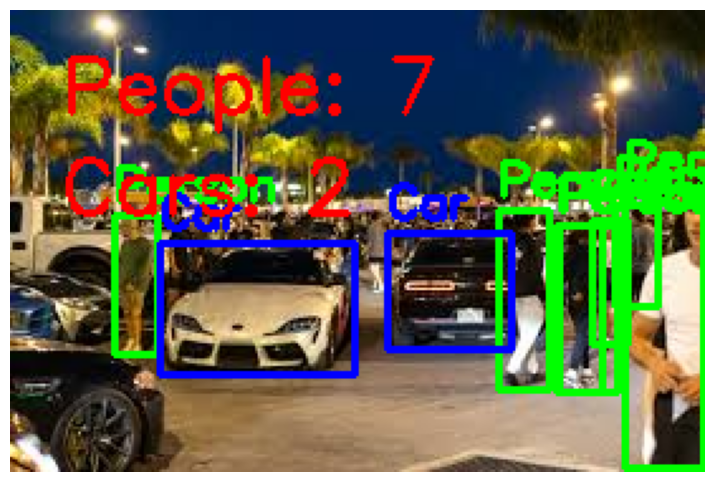

In [40]:
image_path = "image/images (1).jpg"
det = Detector(conf=0.4)
frame = cv2.imread(image_path)
detections = det.detect(frame)
# Separate detections by class
people = [d for d in detections if d[6] == "person"]
cars = [d for d in detections if d[6] == "car"]

print(f"People detected: {len(people)}")
print(f"Cars detected: {len(cars)}")

# Draw bounding boxes
for (x1, y1, x2, y2, conf, cls, name) in people:
    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)  # green for people
    cv2.putText(frame, "Person", (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

for (x1, y1, x2, y2, conf, cls, name) in cars:
    cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 0, 0), 2)  # blue for cars
    cv2.putText(frame, "Car", (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

# Add total counts on top-left
cv2.putText(frame, f"People: {len(people)}", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
cv2.putText(frame, f"Cars: {len(cars)}", (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)

output_path = "output/output_image.jpg"
cv2.imwrite(output_path, frame)
print(f"✅ Output image saved successfully at: {output_path}")

# Show image in notebook
plt.figure(figsize=(10,6))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
